<a href="https://colab.research.google.com/github/USU2505U5EYX/PSPearlysettlementsimulator./blob/main/PSPearlysettlementsimulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
daily_tpv = 45000000
early_settlement_adoption = 0.20
early_settlement_discount = 0.002

early_settlement_demand = daily_tpv * early_settlement_adoption

merchant_payout = early_settlement_demand * (1 - early_settlement_discount)

acceleration_charge = early_settlement_demand - merchant_payout

print("Early Settlement Demand:", early_settlement_demand)
print("Merchant Payout:", merchant_payout)
print("Acceleration Charge:", acceleration_charge)


Early Settlement Demand: 9000000.0
Merchant Payout: 8982000.0
Acceleration Charge: 18000.0


In [3]:
import numpy as np

print(np.__version__)

2.4.6


In [4]:
daily_tpv = np.array([
    45000000,
    52000000,
    38000000,
    61000000,
    72000000
])

print(daily_tpv)

[45000000 52000000 38000000 61000000 72000000]


In [5]:
print(f"Early Settlement Demand: ₹{early_settlement_demand:,.2f}")
print(f"Merchant Payout: ₹{merchant_payout:,.2f}")
print(f"Acceleration Charge: ₹{acceleration_charge:,.2f}")

Early Settlement Demand: ₹9,000,000.00
Merchant Payout: ₹8,982,000.00
Acceleration Charge: ₹18,000.00


In [6]:
adoption_rate = 0.20
discount = 0.002

early_settlement = daily_tpv * adoption_rate

merchant_payout = early_settlement * (1 - discount)

acceleration_charge = early_settlement - merchant_payout

print("Daily Settlement Demand:", early_settlement)
print("Daily Merchant Payout:", merchant_payout)
print("Daily Acceleration Charge:", acceleration_charge)

print("\nTotal PSP Funding:", np.sum(merchant_payout))
print("Peak Daily Funding:", np.max(merchant_payout))
print("Average Daily Funding:", np.mean(merchant_payout))

Daily Settlement Demand: [ 9000000. 10400000.  7600000. 12200000. 14400000.]
Daily Merchant Payout: [ 8982000. 10379200.  7584800. 12175600. 14371200.]
Daily Acceleration Charge: [18000. 20800. 15200. 24400. 28800.]

Total PSP Funding: 53492800.0
Peak Daily Funding: 14371200.0
Average Daily Funding: 10698560.0


In [8]:
early_settlement = daily_tpv * adoption_rate

In [9]:
import numpy as np

rng = np.random.default_rng(42)

daily_tpv_scenarios = rng.normal(
    loc=45000000,
    scale=6750000,
    size=10000
)

daily_tpv_scenarios = np.maximum(daily_tpv_scenarios, 0)

print(daily_tpv_scenarios[:10])

[47056840.28834241 37980107.28287666 50065545.57169358 51348811.83564069
 31830512.4765866  36210288.32867935 45862922.72137918 42865362.50168082
 44886592.18684605 39241953.48887833]


In [11]:
adoption_rate = 0.20
discount = 0.002

early_demand = daily_tpv_scenarios * adoption_rate

merchant_payouts = early_demand * (1 - discount)

acceleration_charges = early_demand * discount

In [12]:
print("Average Daily TPV:", np.mean(daily_tpv_scenarios))

print("Average Early Settlement Demand:", np.mean(early_demand))

print("Average Merchant Payout:", np.mean(merchant_payouts))

print("Average Acceleration Charges:", np.mean(acceleration_charges))

print("Maximum Merchant Payout:", np.max(merchant_payouts))

print("Minimum Merchant Payout:", np.min(merchant_payouts))

Average Daily TPV: 44930813.34095542
Average Early Settlement Demand: 8986162.668191085
Average Merchant Payout: 8968190.342854703
Average Acceleration Charges: 17972.325336382168
Maximum Merchant Payout: 14405992.732766446
Minimum Merchant Payout: 3068545.919811606


In [13]:
p95 = np.percentile(merchant_payouts, 95)

p99 = np.percentile(merchant_payouts, 99)

print("95th Percentile Funding:", p95)

print("99th Percentile Funding:", p99)

95th Percentile Funding: 11195263.595645336
99th Percentile Funding: 12156024.534860544


In [14]:
import numpy as np

rng = np.random.default_rng(42)

number_of_scenarios = 10000
number_of_days = 30

# Generate daily TPV
daily_tpv = rng.normal(
    45000000,
    6750000,
    size=(number_of_scenarios, number_of_days)
)

daily_tpv = np.maximum(daily_tpv, 0)

# Generate variable merchant adoption
adoption_rates = rng.beta(
    2,
    8,
    size=(number_of_scenarios, number_of_days)
)

# Calculate early settlement demand
early_demand = daily_tpv * adoption_rates

# Calculate merchant payouts
discount = 0.002

merchant_payouts = early_demand * (1 - discount)

print("Average adoption:", np.mean(adoption_rates))
print("Average daily payout:", np.mean(merchant_payouts))

Average adoption: 0.20004255830676437
Average daily payout: 8981812.967589395


In [15]:
settlement_delays = rng.choice(
    [1, 2, 3],
    size=(number_of_scenarios, number_of_days),
    p=[0.80, 0.15, 0.05]
)

print("Average settlement delay:",
      np.mean(settlement_delays))

Average settlement delay: 1.25001


In [16]:
outstanding_funding = np.zeros(
    (number_of_scenarios, number_of_days)
)

for day in range(number_of_days):

    origin_days = np.arange(number_of_days)

    still_outstanding = (
        (origin_days <= day) &
        (day < origin_days + settlement_delays)
    )

    outstanding_funding[:, day] = np.sum(
        np.where(
            still_outstanding,
            merchant_payouts,
            0
        ),
        axis=1
    )

print("Average peak funding exposure:",
      np.mean(np.max(outstanding_funding, axis=1)))

print("Maximum simulated funding exposure:",
      np.max(outstanding_funding))

Average peak funding exposure: 30221685.44110066
Maximum simulated funding exposure: 69578301.73263393


In [17]:
# PSP committed funding capacity

psp_funding_capacity = 15000000

# Maximum outstanding exposure in each scenario

scenario_peak_exposure = np.max(
    outstanding_funding,
    axis=1
)

# Average peak exposure

average_peak_exposure = np.mean(
    scenario_peak_exposure
)

# Highest observed exposure

maximum_peak_exposure = np.max(
    scenario_peak_exposure
)

# Funding requirement percentiles

p95_funding = np.percentile(
    scenario_peak_exposure, 95
)

p99_funding = np.percentile(
    scenario_peak_exposure, 99
)

print("Average Peak Exposure: ₹", average_peak_exposure)

print("Maximum Peak Exposure: ₹", maximum_peak_exposure)

print("95th Percentile: ₹", p95_funding)

print("99th Percentile: ₹", p99_funding)

Average Peak Exposure: ₹ 30221685.44110066
Maximum Peak Exposure: ₹ 69578301.73263393
95th Percentile: ₹ 42768962.32909866
99th Percentile: ₹ 50227692.94445547


In [18]:
# Identify scenarios exceeding available funding

funding_shortfall = (
    scenario_peak_exposure > psp_funding_capacity
)

# Calculate probability of shortfall

shortfall_probability = np.mean(
    funding_shortfall
)

print(
    "Probability of Funding Shortfall:",
    shortfall_probability * 100,
    "%"
)

Probability of Funding Shortfall: 99.92 %


In [19]:
average_utilisation = (
    average_peak_exposure / psp_funding_capacity
) * 100

p99_utilisation = (
    p99_funding / psp_funding_capacity
) * 100

print("Average Peak Utilisation:", average_utilisation, "%")

print("P99 Funding Utilisation:", p99_utilisation, "%")

Average Peak Utilisation: 201.47790294067107 %
P99 Funding Utilisation: 334.8512862963698 %


In [20]:
funding_limits = np.array([
    10000000,
    15000000,
    20000000,
    25000000,
    30000000
])

for limit in funding_limits:

    probability = np.mean(
        scenario_peak_exposure > limit
    )

    print(
        f"Funding Limit: ₹{limit:,.0f} | "
        f"Shortfall Probability: {probability * 100:.2f}%"
    )

Funding Limit: ₹10,000,000 | Shortfall Probability: 100.00%
Funding Limit: ₹15,000,000 | Shortfall Probability: 99.92%
Funding Limit: ₹20,000,000 | Shortfall Probability: 96.65%
Funding Limit: ₹25,000,000 | Shortfall Probability: 76.94%
Funding Limit: ₹30,000,000 | Shortfall Probability: 45.80%


In [21]:
# Commercial assumptions

daily_tpv = 45000000

adoption_rate = 0.20

merchant_discount = 0.002

psp_revenue_share = 0.60

soenic_revenue_share = 0.40

# Eligible early settlement volume

early_settlement_volume = daily_tpv * adoption_rate

# Total merchant discount

gross_discount_revenue = (
    early_settlement_volume * merchant_discount
)

# Revenue distribution

psp_revenue = (
    gross_discount_revenue * psp_revenue_share
)

soenic_revenue = (
    gross_discount_revenue * soenic_revenue_share
)

print("Early Settlement Volume:", early_settlement_volume)

print("Gross Discount Revenue:", gross_discount_revenue)

print("PSP Revenue:", psp_revenue)

print("Soenic Revenue:", soenic_revenue)

Early Settlement Volume: 9000000.0
Gross Discount Revenue: 18000.0
PSP Revenue: 10800.0
Soenic Revenue: 7200.0


In [22]:
annual_funding_cost = 0.12

funding_duration_days = 1

merchant_payout = (
    early_settlement_volume * (1 - merchant_discount)
)

psp_funding_cost = (
    merchant_payout
    * annual_funding_cost
    * funding_duration_days / 365
)

print("PSP Funding Cost:", psp_funding_cost)

PSP Funding Cost: 2952.986301369863


In [23]:
psp_net_contribution = (
    psp_revenue - psp_funding_cost
)

soenic_net_revenue = soenic_revenue

combined_contribution = (
    psp_net_contribution + soenic_net_revenue
)

print("PSP Net Contribution:", psp_net_contribution)

print("Soenic Revenue:", soenic_net_revenue)

print("Combined Contribution:", combined_contribution)

PSP Net Contribution: 7847.013698630137
Soenic Revenue: 7200.0
Combined Contribution: 15047.013698630137


In [24]:
adoption_rates = np.array([
    0.05,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50
])

for adoption in adoption_rates:

    volume = daily_tpv * adoption

    discount_revenue = volume * merchant_discount

    payout = volume * (1 - merchant_discount)

    funding_cost = (
        payout * annual_funding_cost / 365
    )

    psp_revenue = discount_revenue * psp_revenue_share

    soenic_revenue = discount_revenue * soenic_revenue_share

    psp_profit = psp_revenue - funding_cost

    print(
        f"Adoption: {adoption:.0%} | "
        f"PSP Contribution: ₹{psp_profit:,.2f} | "
        f"Soenic Revenue: ₹{soenic_revenue:,.2f}"
    )

Adoption: 5% | PSP Contribution: ₹1,961.75 | Soenic Revenue: ₹1,800.00
Adoption: 10% | PSP Contribution: ₹3,923.51 | Soenic Revenue: ₹3,600.00
Adoption: 20% | PSP Contribution: ₹7,847.01 | Soenic Revenue: ₹7,200.00
Adoption: 30% | PSP Contribution: ₹11,770.52 | Soenic Revenue: ₹10,800.00
Adoption: 40% | PSP Contribution: ₹15,694.03 | Soenic Revenue: ₹14,400.00
Adoption: 50% | PSP Contribution: ₹19,617.53 | Soenic Revenue: ₹18,000.00


In [25]:
import numpy as np

# ==========================================
# 1. SIMULATION CONFIGURATION
# ==========================================

rng = np.random.default_rng(42)

number_of_scenarios = 10000
number_of_days = 30

daily_tpv_mean = 45_000_000
daily_tpv_std = 6_750_000

merchant_discount = 0.002
annual_funding_cost = 0.12

psp_funding_capacity = 15_000_000

psp_revenue_share = 0.60
soenic_revenue_share = 0.40


# ==========================================
# 2. GENERATE DAILY TPV
# ==========================================

daily_tpv = rng.normal(
    daily_tpv_mean,
    daily_tpv_std,
    size=(number_of_scenarios, number_of_days)
)

daily_tpv = np.maximum(daily_tpv, 0)


# ==========================================
# 3. GENERATE MERCHANT ADOPTION
# ==========================================

adoption_rates = rng.beta(
    2,
    8,
    size=(number_of_scenarios, number_of_days)
)

early_settlement_volume = (
    daily_tpv * adoption_rates
)


# ==========================================
# 4. CALCULATE MERCHANT PAYOUTS
# ==========================================

merchant_payouts = (
    early_settlement_volume *
    (1 - merchant_discount)
)

gross_discount_revenue = (
    early_settlement_volume *
    merchant_discount
)


# ==========================================
# 5. GENERATE SETTLEMENT DELAYS
# ==========================================

settlement_delays = rng.choice(
    [1, 2, 3],
    size=(number_of_scenarios, number_of_days),
    p=[0.80, 0.15, 0.05]
)


# ==========================================
# 6. CALCULATE OUTSTANDING FUNDING
# ==========================================

outstanding_funding = np.zeros(
    (number_of_scenarios, number_of_days)
)

for day in range(number_of_days):

    origin_days = np.arange(number_of_days)

    active_cohorts = (
        (origin_days <= day) &
        (day < origin_days + settlement_delays)
    )

    outstanding_funding[:, day] = np.sum(
        np.where(
            active_cohorts,
            merchant_payouts,
            0
        ),
        axis=1
    )


# ==========================================
# 7. CALCULATE PEAK FUNDING EXPOSURE
# ==========================================

scenario_peak_exposure = np.max(
    outstanding_funding,
    axis=1
)

average_peak_exposure = np.mean(
    scenario_peak_exposure
)

p95_funding = np.percentile(
    scenario_peak_exposure, 95
)

p99_funding = np.percentile(
    scenario_peak_exposure, 99
)


# ==========================================
# 8. CALCULATE FUNDING SHORTFALL
# ==========================================

shortfall_probability = np.mean(
    scenario_peak_exposure >
    psp_funding_capacity
)


# ==========================================
# 9. CALCULATE FUNDING COST
# ==========================================

funding_cost_per_scenario = np.sum(
    merchant_payouts *
    annual_funding_cost *
    settlement_delays / 365,
    axis=1
)

average_funding_cost = np.mean(
    funding_cost_per_scenario
)


# ==========================================
# 10. REVENUE DISTRIBUTION
# ==========================================

total_discount_revenue = np.sum(
    gross_discount_revenue,
    axis=1
)

psp_revenue = (
    total_discount_revenue *
    psp_revenue_share
)

soenic_revenue = (
    total_discount_revenue *
    soenic_revenue_share
)


# ==========================================
# 11. COMMERCIAL CONTRIBUTION
# ==========================================

psp_net_contribution = (
    psp_revenue -
    funding_cost_per_scenario
)

average_psp_contribution = np.mean(
    psp_net_contribution
)

average_soenic_revenue = np.mean(
    soenic_revenue
)


# ==========================================
# 12. FINAL REPORT
# ==========================================

print("=" * 50)
print("PSP SETTLEMENT INTELLIGENCE REPORT")
print("=" * 50)

print("\nTRANSACTION ECONOMICS")

print(
    "Average Daily TPV: ₹",
    round(np.mean(daily_tpv))
)

print(
    "Average Adoption:",
    round(np.mean(adoption_rates) * 100, 2),
    "%"
)

print(
    "Average Daily Early Settlement:",
    round(np.mean(early_settlement_volume))
)

print("\nFUNDING REQUIREMENTS")

print(
    "Average Peak Exposure: ₹",
    round(average_peak_exposure)
)

print(
    "P95 Funding Requirement: ₹",
    round(p95_funding)
)

print(
    "P99 Funding Requirement: ₹",
    round(p99_funding)
)

print(
    "Funding Shortfall Probability:",
    round(shortfall_probability * 100, 2),
    "%"
)

print("\nCOMMERCIAL ECONOMICS")

print(
    "Average 30-Day PSP Funding Cost: ₹",
    round(average_funding_cost)
)

print(
    "Average 30-Day PSP Contribution: ₹",
    round(average_psp_contribution)
)

print(
    "Average 30-Day Soenic Revenue: ₹",
    round(average_soenic_revenue)
)

print("=" * 50)

PSP SETTLEMENT INTELLIGENCE REPORT

TRANSACTION ECONOMICS
Average Daily TPV: ₹ 45000289
Average Adoption: 20.0 %
Average Daily Early Settlement: 8999813

FUNDING REQUIREMENTS
Average Peak Exposure: ₹ 30221685
P95 Funding Requirement: ₹ 42768962
P99 Funding Requirement: ₹ 50227693
Funding Shortfall Probability: 99.92 %

COMMERCIAL ECONOMICS
Average 30-Day PSP Funding Cost: ₹ 110683
Average 30-Day PSP Contribution: ₹ 213310
Average 30-Day Soenic Revenue: ₹ 215996


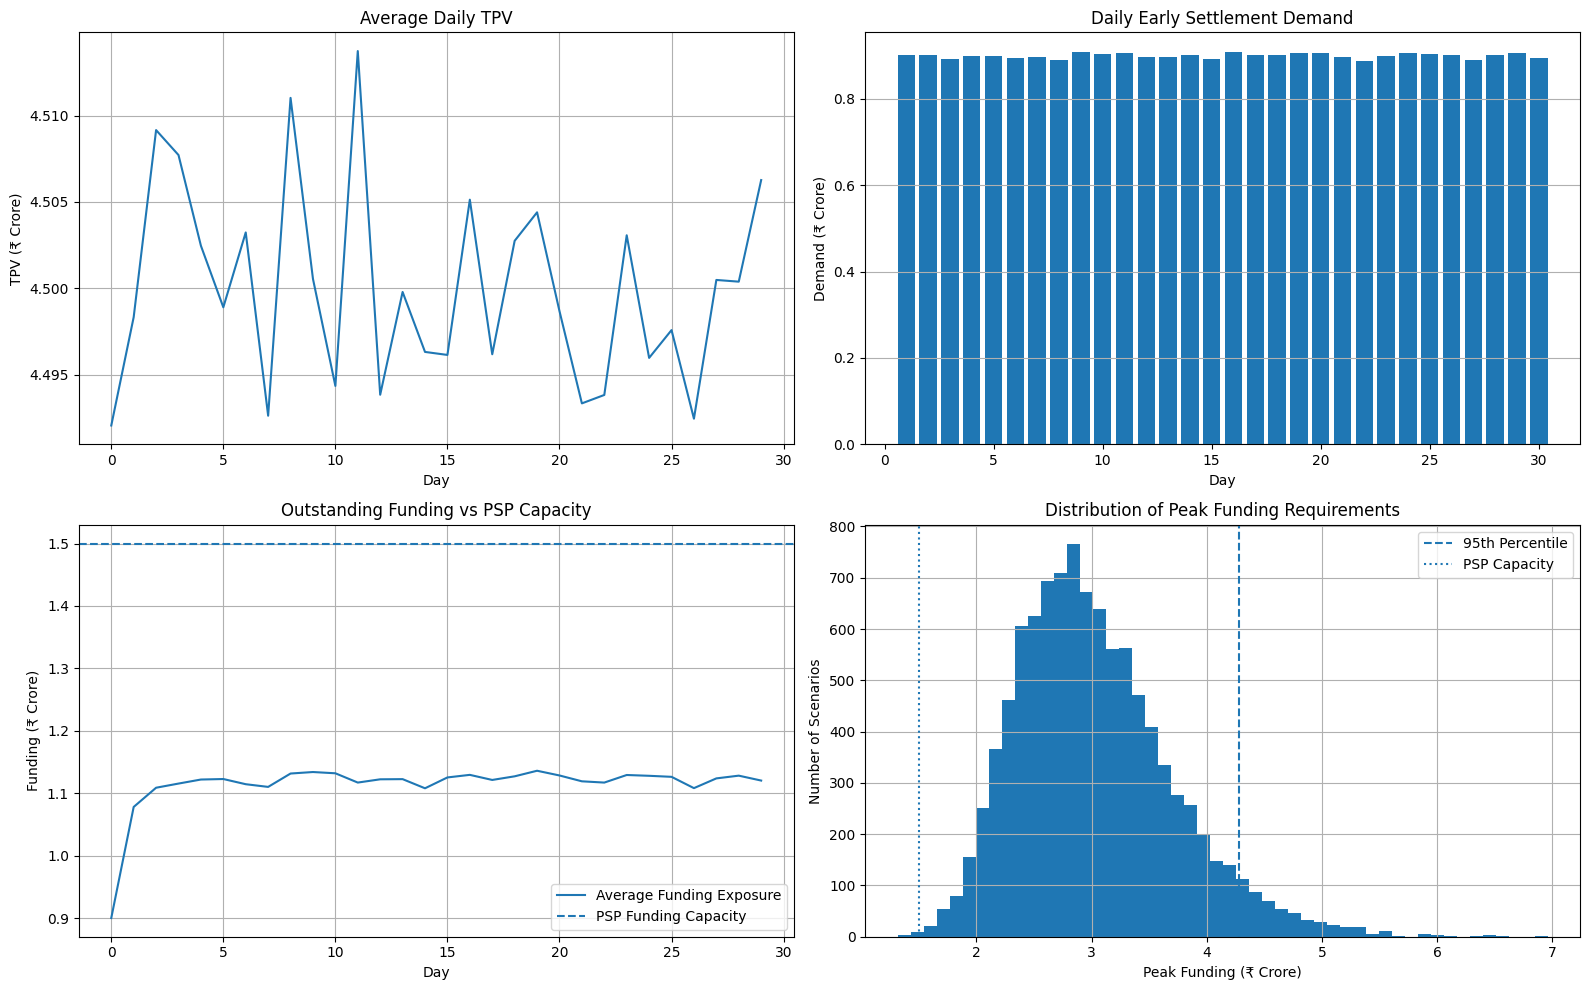

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Create a 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# --------------------------------
# 1. DAILY TPV
# --------------------------------

average_daily_tpv = np.mean(daily_tpv, axis=0)

axes[0, 0].plot(average_daily_tpv / 10_000_000)
axes[0, 0].set_title("Average Daily TPV")
axes[0, 0].set_xlabel("Day")
axes[0, 0].set_ylabel("TPV (₹ Crore)")
axes[0, 0].grid(True)


# --------------------------------
# 2. EARLY SETTLEMENT DEMAND
# --------------------------------

average_early_settlement = np.mean(
    early_settlement_volume, axis=0
)

axes[0, 1].bar(
    range(1, number_of_days + 1),
    average_early_settlement / 10_000_000
)

axes[0, 1].set_title("Daily Early Settlement Demand")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Demand (₹ Crore)")
axes[0, 1].grid(axis="y")


# --------------------------------
# 3. FUNDING EXPOSURE VS CAPACITY
# --------------------------------

average_daily_exposure = np.mean(
    outstanding_funding, axis=0
)

axes[1, 0].plot(
    average_daily_exposure / 10_000_000,
    label="Average Funding Exposure"
)

axes[1, 0].axhline(
    psp_funding_capacity / 10_000_000,
    linestyle="--",
    label="PSP Funding Capacity"
)

axes[1, 0].set_title("Outstanding Funding vs PSP Capacity")
axes[1, 0].set_xlabel("Day")
axes[1, 0].set_ylabel("Funding (₹ Crore)")
axes[1, 0].legend()
axes[1, 0].grid(True)


# --------------------------------
# 4. PEAK FUNDING DISTRIBUTION
# --------------------------------

axes[1, 1].hist(
    scenario_peak_exposure / 10_000_000,
    bins=50
)

axes[1, 1].axvline(
    p95_funding / 10_000_000,
    linestyle="--",
    label="95th Percentile"
)

axes[1, 1].axvline(
    psp_funding_capacity / 10_000_000,
    linestyle=":",
    label="PSP Capacity"
)

axes[1, 1].set_title("Distribution of Peak Funding Requirements")
axes[1, 1].set_xlabel("Peak Funding (₹ Crore)")
axes[1, 1].set_ylabel("Number of Scenarios")
axes[1, 1].legend()
axes[1, 1].grid(True)


# --------------------------------
# DISPLAY DASHBOARD
# --------------------------------

plt.tight_layout()
plt.show()

In [27]:
# Funding gap analysis

funding_gap = np.maximum(
    scenario_peak_exposure - psp_funding_capacity,
    0
)

print("FUNDING GAP ANALYSIS")
print("-" * 40)

print(
    "Scenarios exceeding capacity:",
    round(shortfall_probability * 100, 2),
    "%"
)

print(
    "Average funding gap when capacity is breached: ₹",
    round(np.mean(funding_gap[funding_gap > 0]))
)

print(
    "Maximum funding requirement: ₹",
    round(np.max(scenario_peak_exposure))
)

print(
    "P95 funding requirement: ₹",
    round(p95_funding)
)

print(
    "Additional capacity needed to cover P95: ₹",
    round(max(p95_funding - psp_funding_capacity, 0))
)

FUNDING GAP ANALYSIS
----------------------------------------
Scenarios exceeding capacity: 99.92 %
Average funding gap when capacity is breached: ₹ 15234407
Maximum funding requirement: ₹ 69578302
P95 funding requirement: ₹ 42768962
Additional capacity needed to cover P95: ₹ 27768962


In [28]:
# CAPITAL ADEQUACY ANALYSIS

capacities = np.array([
    15_000_000,
    20_000_000,
    25_000_000,
    30_000_000,
    35_000_000,
    40_000_000,
    45_000_000,
    50_000_000
])

print("PSP CAPITAL ADEQUACY")
print("-" * 55)

for capacity in capacities:

    probability = np.mean(
        scenario_peak_exposure > capacity
    )

    print(
        f"Capacity: ₹{capacity/10_000_000:.1f} Cr"
        f" | Shortfall probability: {probability*100:.2f}%"
    )

PSP CAPITAL ADEQUACY
-------------------------------------------------------
Capacity: ₹1.5 Cr | Shortfall probability: 99.92%
Capacity: ₹2.0 Cr | Shortfall probability: 96.65%
Capacity: ₹2.5 Cr | Shortfall probability: 76.94%
Capacity: ₹3.0 Cr | Shortfall probability: 45.80%
Capacity: ₹3.5 Cr | Shortfall probability: 21.48%
Capacity: ₹4.0 Cr | Shortfall probability: 8.72%
Capacity: ₹4.5 Cr | Shortfall probability: 3.13%
Capacity: ₹5.0 Cr | Shortfall probability: 1.06%


In [30]:
# ============================================================
# PSP TREASURY & SETTLEMENT INTELLIGENCE DASHBOARD
# ============================================================

import numpy as np
import plotly.graph_objects as go
import ipywidgets as widgets

from IPython.display import display, HTML, clear_output


# ============================================================
# 1. VALIDATE SIMULATION DATA
# ============================================================

required_variables = [
    "scenario_peak_exposure",
    "outstanding_funding",
    "number_of_days"
]

for variable in required_variables:
    if variable not in globals():
        raise ValueError(
            f"Missing variable: {variable}. Run your simulation first."
        )


# ============================================================
# 2. DASHBOARD CONTROLS
# ============================================================

capacity_slider = widgets.FloatSlider(
    value=3.0,
    min=1.0,
    max=8.0,
    step=0.25,
    description="Available Capital (₹ Cr):",
    style={"description_width": "initial"},
    continuous_update=False
)

risk_slider = widgets.FloatSlider(
    value=5.0,
    min=0.1,
    max=20.0,
    step=0.5,
    description="Maximum Shortfall Risk (%):",
    style={"description_width": "initial"},
    continuous_update=False
)

dashboard_output = widgets.Output()


# ============================================================
# 3. DASHBOARD ENGINE
# ============================================================

def generate_dashboard(capacity_cr, acceptable_risk):

    capacity = capacity_cr * 10_000_000

    # Calculate shortfall probability
    shortfall_probability = np.mean(
        scenario_peak_exposure > capacity
    ) * 100

    # Calculate required capital for selected risk tolerance
    required_capital = np.percentile(
        scenario_peak_exposure,
        100 - acceptable_risk
    ) / 10_000_000

    # Average daily exposure
    average_exposure = np.mean(
        outstanding_funding,
        axis=0
    ) / 10_000_000

    # Peak funding distribution
    peak_distribution = (
        scenario_peak_exposure / 10_000_000
    )

    # Decision
    capital_adequate = (
        shortfall_probability <= acceptable_risk
    )

    if capital_adequate:
        decision = "CAPITAL ADEQUATE"
        decision_color = "#198754"
        assessment = "Available capital meets the selected risk threshold."
    else:
        decision = "LIQUIDITY RISK"
        decision_color = "#dc3545"
        assessment = "Available capital does not meet the selected risk threshold."

    # ========================================================
    # KPI CARDS
    # ========================================================

    display(HTML(f"""
    <div style="
        display:grid;
        grid-template-columns:repeat(auto-fit,minmax(180px,1fr));
        gap:12px;
        margin:15px 0;
    ">

        <div style="background:#172554;color:white;padding:20px;border-radius:10px;">
            <small>Available PSP Capital</small>
            <h2>₹{capacity_cr:.2f} Cr</h2>
        </div>

        <div style="background:#334155;color:white;padding:20px;border-radius:10px;">
            <small>Shortfall Probability</small>
            <h2>{shortfall_probability:.2f}%</h2>
        </div>

        <div style="background:#334155;color:white;padding:20px;border-radius:10px;">
            <small>Required Capital</small>
            <h2>₹{required_capital:.2f} Cr</h2>
        </div>

        <div style="background:{decision_color};color:white;padding:20px;border-radius:10px;">
            <small>Capital Assessment</small>
            <h2>{decision}</h2>
        </div>

    </div>

    <div style="padding:15px;background:#f1f5f9;color:#172554;border-radius:8px;">
        <b>Assessment:</b> {assessment}<br><br>
        <b>Additional capital required:</b>
        ₹{max(required_capital-capacity_cr,0):.2f} Cr
    </div>
    """))

    # ========================================================
    # CHART 1: DAILY FUNDING EXPOSURE
    # ========================================================

    fig1 = go.Figure()

    fig1.add_trace(go.Scatter(
        x=list(range(1, number_of_days + 1)),
        y=average_exposure,
        mode="lines+markers",
        name="Average Exposure"
    ))

    fig1.add_hline(
        y=capacity_cr,
        line_dash="dash",
        annotation_text="Available Capital"
    )

    fig1.update_layout(
        title="Daily Outstanding Funding Exposure",
        xaxis_title="Simulation Day",
        yaxis_title="Funding (₹ Crore)",
        template="plotly_white",
        height=400
    )

    fig1.show()

    # ========================================================
    # CHART 2: PEAK FUNDING DISTRIBUTION
    # ========================================================

    fig2 = go.Figure()

    fig2.add_trace(go.Histogram(
        x=peak_distribution,
        nbinsx=50,
        name="Peak Funding Requirements"
    ))

    fig2.add_vline(
        x=capacity_cr,
        line_dash="dot",
        annotation_text="Available Capital"
    )

    fig2.add_vline(
        x=required_capital,
        line_dash="dash",
        annotation_text="Required Capital"
    )

    fig2.update_layout(
        title="Distribution of Peak Funding Requirements",
        xaxis_title="Peak Funding (₹ Crore)",
        yaxis_title="Number of Scenarios",
        template="plotly_white",
        height=400
    )

    fig2.show()

    # ========================================================
    # CHART 3: CAPITAL ADEQUACY CURVE
    # ========================================================

    capacities = np.arange(1, 8.1, 0.1)

    shortfall_rates = [
        np.mean(
            scenario_peak_exposure > c * 10_000_000
        ) * 100
        for c in capacities
    ]

    fig3 = go.Figure()

    fig3.add_trace(go.Scatter(
        x=capacities,
        y=shortfall_rates,
        mode="lines",
        name="Shortfall Probability"
    ))

    fig3.add_hline(
        y=acceptable_risk,
        line_dash="dash",
        annotation_text="Selected Risk Limit"
    )

    fig3.add_vline(
        x=capacity_cr,
        line_dash="dot",
        annotation_text="Current Capital"
    )

    fig3.update_layout(
        title="PSP Capital Adequacy Curve",
        xaxis_title="Available Capital (₹ Crore)",
        yaxis_title="Shortfall Probability (%)",
        template="plotly_white",
        height=400
    )

    fig3.show()


# ============================================================
# 4. INTERACTIVE DASHBOARD
# ============================================================

def refresh_dashboard(change=None):

    with dashboard_output:
        clear_output(wait=True)

        generate_dashboard(
            capacity_slider.value,
            risk_slider.value
        )


capacity_slider.observe(
    refresh_dashboard,
    names="value"
)

risk_slider.observe(
    refresh_dashboard,
    names="value"
)


# ============================================================
# 5. DISPLAY
# ============================================================

display(HTML("""
<h1>PSP Treasury & Settlement Intelligence</h1>
<p>Liquidity monitoring | Capital adequacy | Settlement risk</p>
<hr>
"""))

display(capacity_slider)
display(risk_slider)
display(dashboard_output)

refresh_dashboard()

FloatSlider(value=3.0, continuous_update=False, description='Available Capital (₹ Cr):', max=8.0, min=1.0, ste…

FloatSlider(value=5.0, continuous_update=False, description='Maximum Shortfall Risk (%):', max=20.0, min=0.1, …

Output()